# 05 — 统一评估与错误分析

**负责人：** 成员 5。

**输入：** 成员 2 的 200 条固定测试集；成员 3 的 unigram TF-IDF；04 中选定的 NB alpha；Linear SVM 使用成员 4 在训练折内锁定的 `C=0.1`。

**输出：** 统一模型比较、ROC、混淆矩阵、关键词、错误类别汇总和英文报告数字。

测试集只在所有参数锁定后使用一次，不参与任何选参或特征拟合。含完整评论文本的明细只写入 Git 忽略的 `data/processed/`。

In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd()
if (notebook_dir / "pyproject.toml").is_file():
    project_root = notebook_dir
elif (notebook_dir.parent / "pyproject.toml").is_file():
    project_root = notebook_dir.parent
else:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录运行")
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
from IPython.display import Image, display
from restaurant_sentiment.preprocessing import load_fixed_partitions
from restaurant_sentiment.final_evaluation import run_final_evaluation

# 成员 4 已在训练折内锁定 C=0.1。
SVM_C = 0.1
metadata = run_final_evaluation(project_root, svm_c=SVM_C)
print('NB alpha (training folds):', metadata['nb_alpha_selected_by_training_f1'])
print('SVM C:', metadata['svm_c_used_in_final_fit'])
print('Train / test rows:', metadata['train_rows'], '/', metadata['test_rows'])
print('Test metrics computed:', metadata['test_metrics_computed'])

NB alpha (training folds): 0.5
SVM C: 0.1
Train / test rows: 796 / 200
Test metrics computed: True


## 统一测试集比较

三个模型使用完全相同的 200 条评论、同一正类定义（Liked=1）和同一套指标。Dummy 采用多数类预测，作为最低基线。ROC-AUC 使用 NB 的预测概率、SVM 的决策函数和 Dummy 的常数概率计算。

In [2]:
comparison = pd.read_csv(project_root / 'results/tables/final_model_comparison.csv')
comparison.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,dummy,0.50,0.5000,1.00,0.6667,0.5000
1,nb,0.75,0.7660,0.72,0.7423,0.8369
2,svm,0.74,0.7791,0.67,0.7204,0.8061


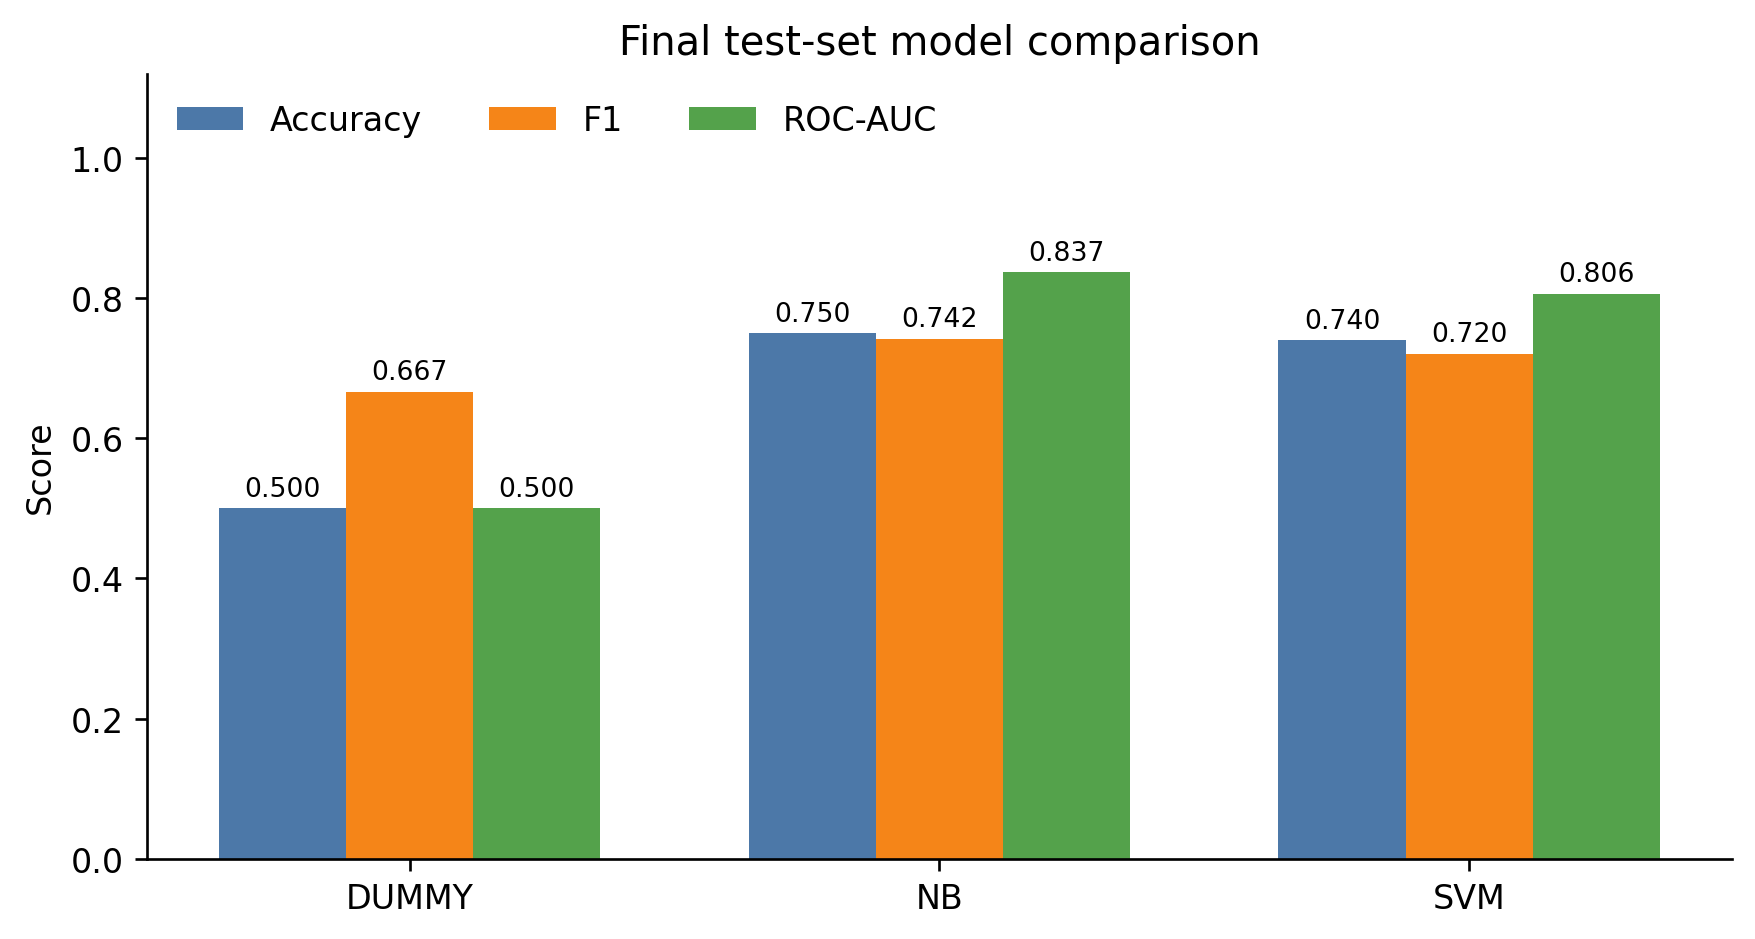

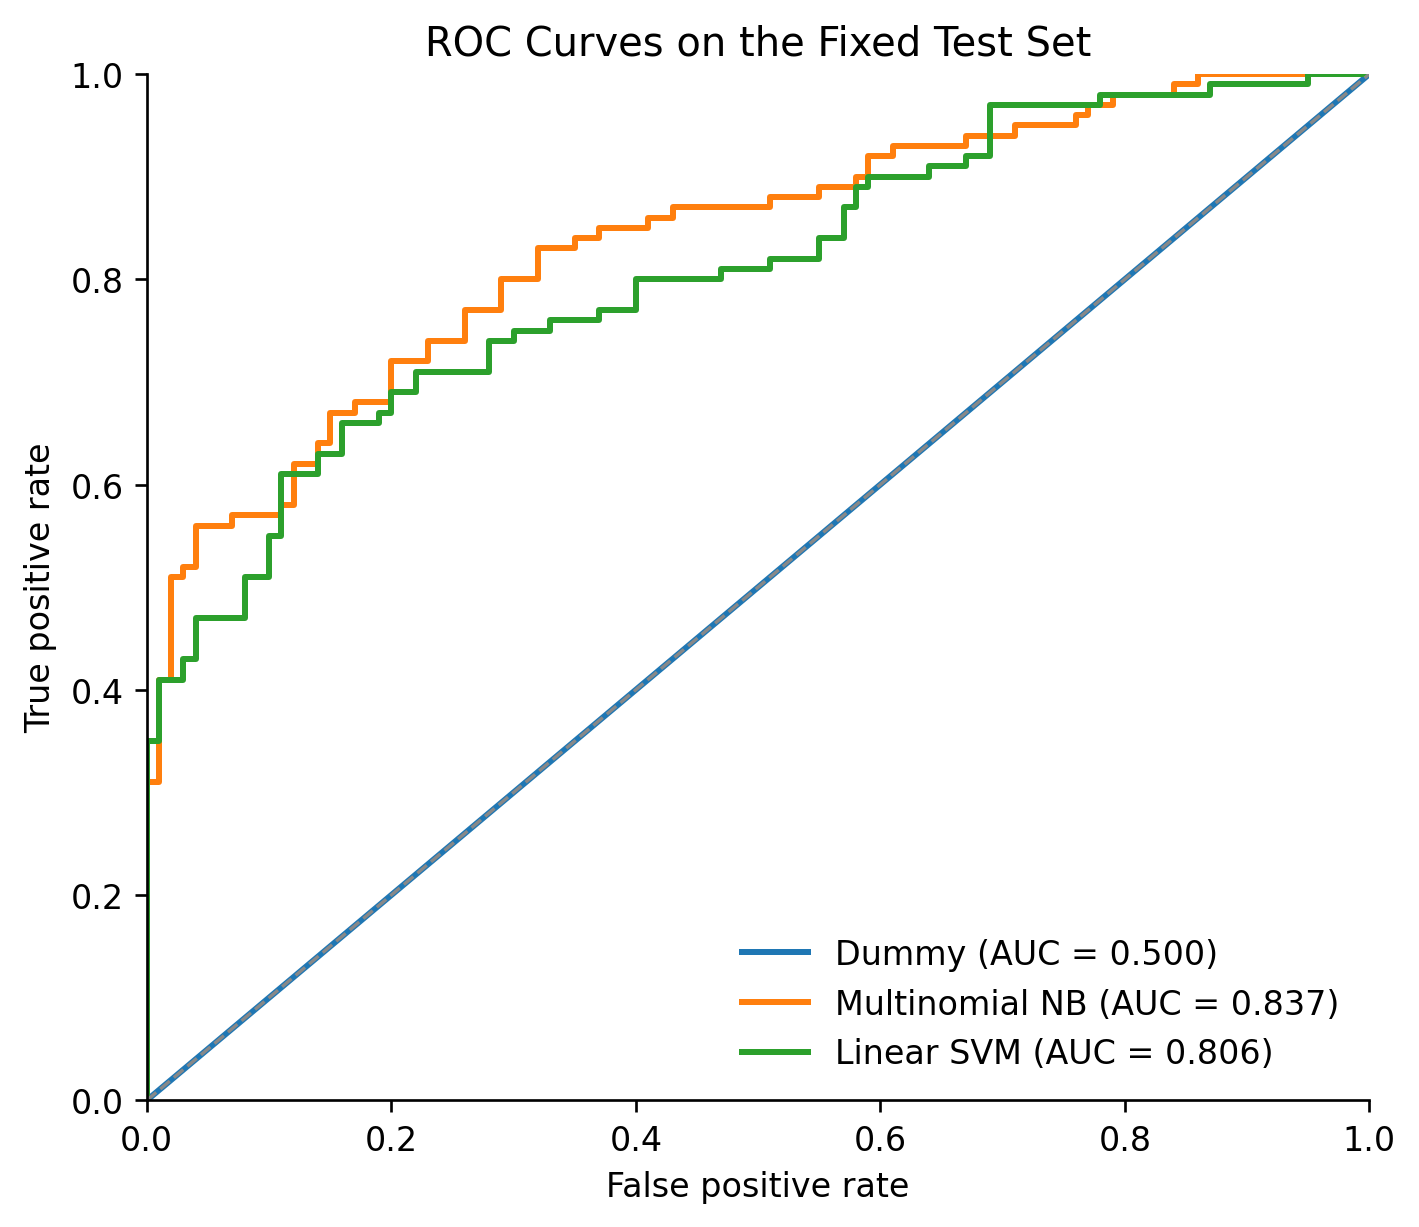

In [3]:
display(Image(filename=str(project_root / 'results/figures/final_model_comparison.png')))
display(Image(filename=str(project_root / 'results/figures/final_roc_curves.png')))

## 混淆矩阵

下面两张混淆矩阵使用相同的测试标签和英文图注。False positive 表示负面评论被判为正面，false negative 表示正面评论被判为负面。

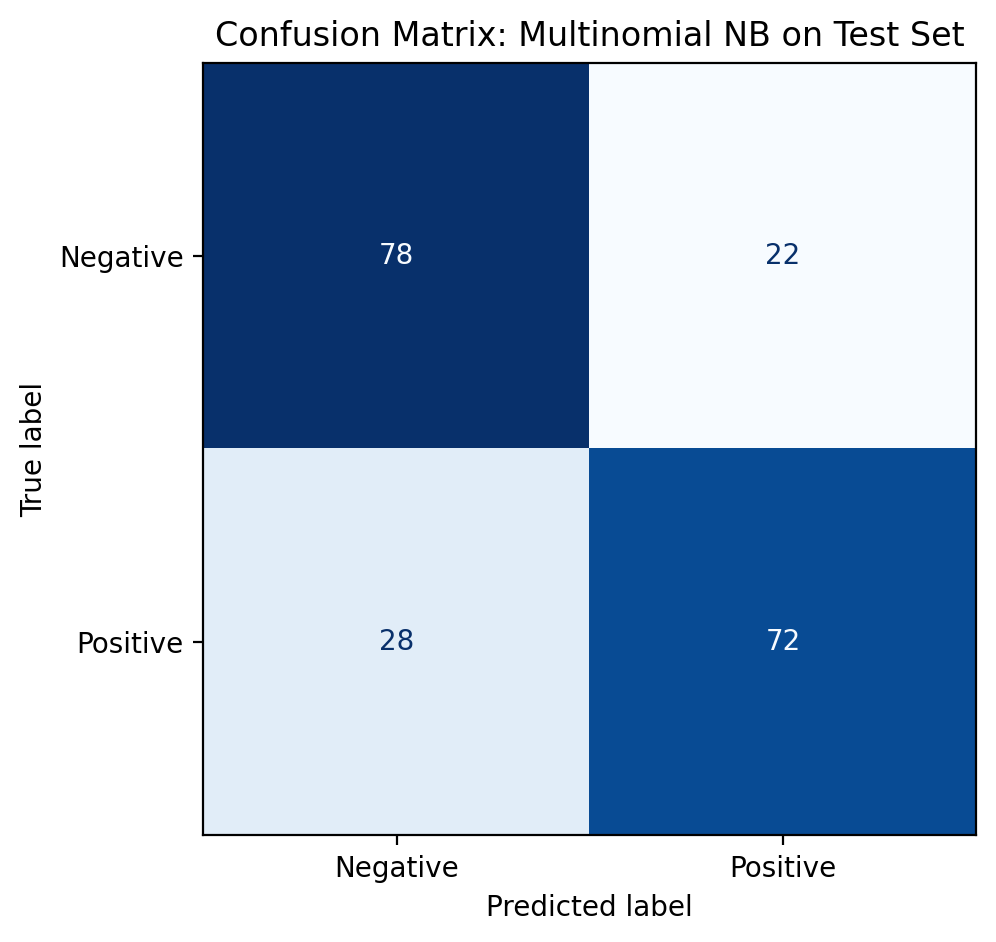

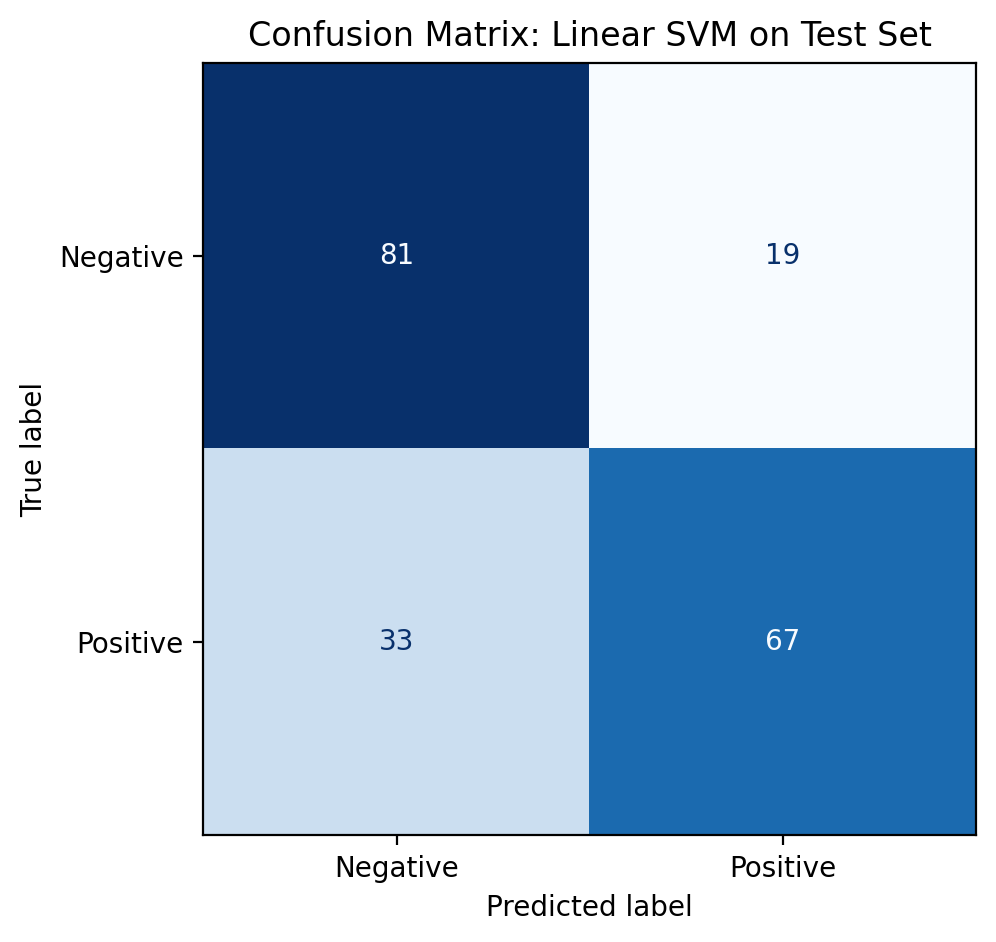

In [4]:
display(Image(filename=str(project_root / 'results/figures/final_confusion_matrix_nb.png')))
display(Image(filename=str(project_root / 'results/figures/final_confusion_matrix_svm.png')))

## 错误分析

错误类别是**描述性启发式标记**，用于组织人工检查，不代表因果关系：否定/缩写、转折或限定、短评论、同时出现正负词、其他。每个错误只归入优先级最高的一个主类别；否定、转折和混合词同时保留为独立布尔标记。高置信度错误定义为模型分数距中性边界达到该模型上四分位的错误。

In [5]:
summary = pd.read_csv(project_root / 'results/tables/final_error_summary.csv')
summary.drop(columns=['reviews']).round(3)

,model,correct,errors,false_positive,false_negative,high_confidence_errors,errors_with_negation,errors_with_contrast,mixed_sentiment_errors,median_words_errors,median_words_correct,category_mixed sentiment terms,category_negation or contraction,category_contrast or qualification,category_short review,category_other
0,dummy,100,100,100,0,0,34,10,2,10.0,10.5,2,34,5,22,37
1,nb,150,50,22,28,2,10,2,0,9.0,10.0,0,10,1,16,23
2,svm,148,52,19,33,2,10,2,0,10.5,10.0,0,10,1,15,26


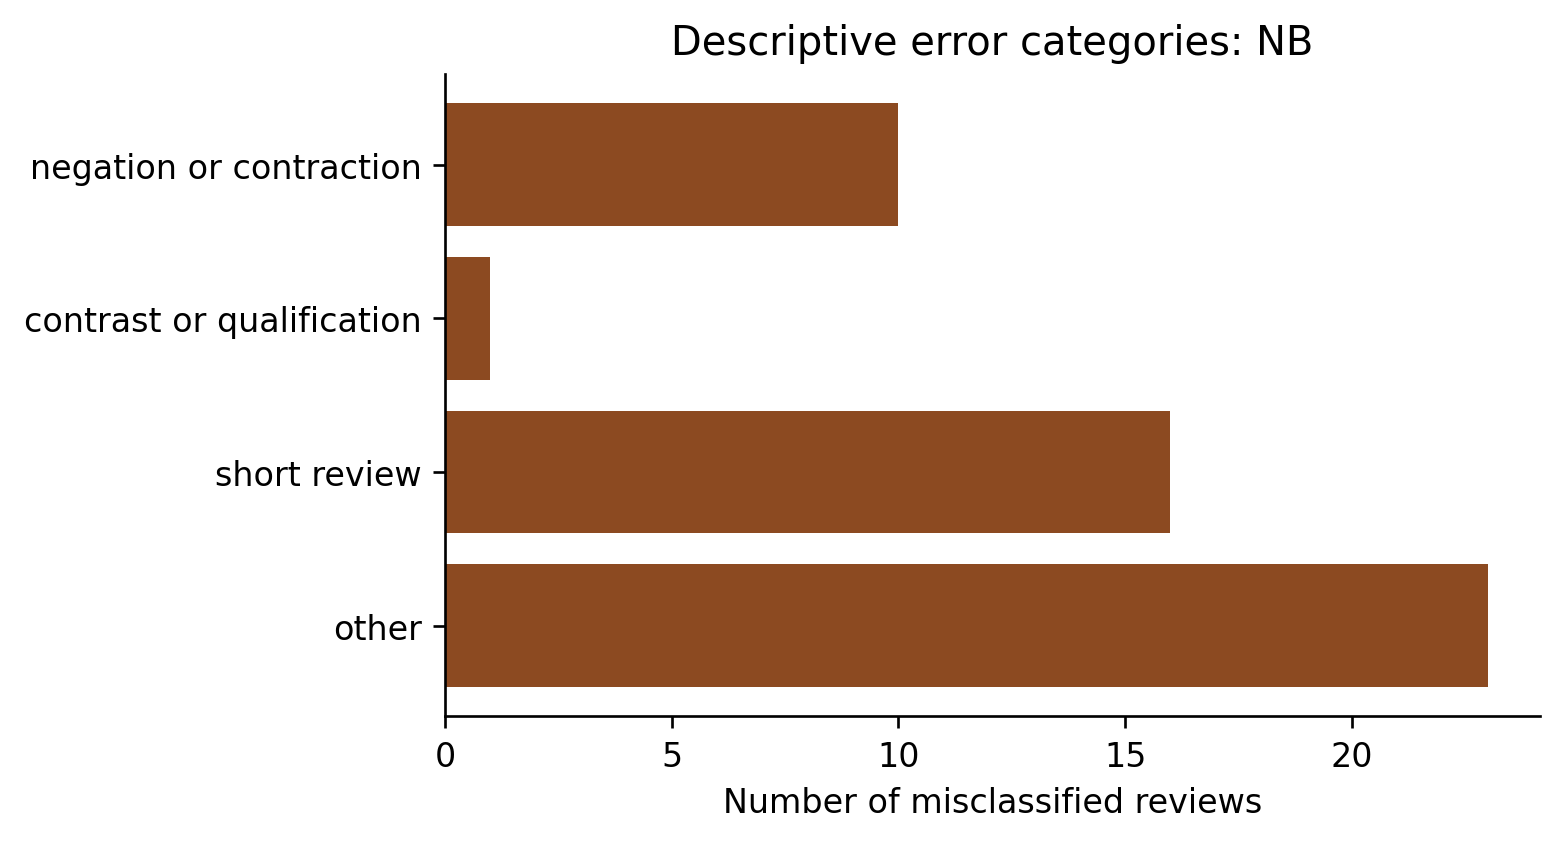

In [6]:
display(Image(filename=str(project_root / 'results/figures/final_error_categories.png')))

In [7]:
nb_errors = pd.read_csv(project_root / 'data/processed/final_errors_nb.csv')
# 只展示不含评论原文的字段，避免在 notebook 输出中复制数据。
nb_errors.loc[~nb_errors['is_correct'],
             ['review_id', 'true_label', 'predicted_label', 'error_type',
              'word_count', 'has_negation', 'has_contrast', 'error_category']].head(8)

,review_id,true_label,predicted_label,error_type,word_count,has_negation,has_contrast,error_category
0,31,1,0,false negative,16,False,False,other
1,456,0,1,false positive,12,False,False,other
4,367,0,1,false positive,10,False,False,other
5,438,1,0,false negative,12,False,False,other
7,734,1,0,false negative,8,False,False,other
12,21,0,1,false positive,3,False,False,short review
16,396,1,0,false negative,22,True,True,negation or contraction
20,7,0,1,false positive,6,True,False,negation or contraction


## 关键词与讨论

下面是从训练好的模型中提取的高权重词。NB 列是正类与负类的对数概率差，SVM 列是线性系数。两者都受训练集词频和不平衡影响，只能作为解释线索。

In [8]:
nb_terms = pd.read_csv(project_root / 'results/tables/final_nb_top_terms.csv')
svm_terms = pd.read_csv(project_root / 'results/tables/final_svm_top_terms.csv')
print('NB top terms')
display(nb_terms.head(10).round(3))
print('SVM top terms')
display(svm_terms.head(10).round(3))

NB top terms


,negative_term,negative_log_odds,positive_term,positive_log_odds
0,terrible,-2.303,great,3.620
1,bad,-2.279,delicious,2.808
2,minutes,-2.198,fantastic,2.485
3,wasn,-2.178,awesome,2.413
4,slow,-2.127,loved,2.071
5,waited,-2.009,excellent,2.069
6,probably,-1.958,amazing,2.018
7,rude,-1.888,perfect,2.017
8,impressed,-1.873,spot,1.980
9,management,-1.852,happy,1.893


SVM top terms


,negative_term,negative_weight,positive_term,positive_weight
0,not,-1.363,great,1.294
1,at,-0.596,good,1.005
2,wasn,-0.585,delicious,0.786
3,don,-0.578,fantastic,0.653
4,bad,-0.542,amazing,0.625
5,no,-0.500,nice,0.537
6,terrible,-0.496,friendly,0.531
7,worst,-0.494,awesome,0.525
8,slow,-0.474,you,0.507
9,never,-0.471,is,0.475


## 局限与复现

- 数据集只有 996 条短评论，200 条测试集的指标有较大抽样波动；单一样本上的 F1 差异不应解释为统计显著。
- 默认分词拆开缩写并丢弃单字符片段，`isn't` 等否定表达无法完整建模。
- 错误类别是关键词启发式，未做人工标注或因果验证。
- 若成员 4 最终选择不同 `C`，运行 `python -m restaurant_sentiment.final_evaluation --svm-c <值>` 重新生成全部结果，不得依据测试集选择参数。

完整中文交接见 `docs/member5_handoff.md`；英文 Results、Error Analysis 与 Discussion 见 `report/nb_evaluation.tex`。